# dots.ocr — Multilingual Vision-Language Model Layout Analysis Pipeline

Pipeline phân tích layout tài liệu bằng mô hình thị giác - ngôn ngữ **dots.ocr** (1.7B tham số, phát triển bởi nhóm nghiên cứu **RedNote HI Lab / Dots Studio**).

### Kiến trúc Vision-Language Model (VLM)
- **Backbone**: Kết hợp mạng thị giác độ phân giải cao (High-resolution Vision Encoder) và mô hình ngôn ngữ nền tảng Qwen2-VL 1.7B.
- **End-to-End Layout Parsing**: Không phụ thuộc vào pipeline tách rời (như YOLO + Heuristics), dots.ocr sinh trực tiếp cấu trúc văn bản và bounding box `[x1, y1, x2, y2]` thông qua text prompt.
- **Taxonomy Mapping (1-1)**: dots.ocr được thiết kế hỗ trợ trực tiếp 11 danh mục của **DocLayNet** (`Caption`, `Footnote`, `Formula`, `List-item`, `Page-footer`, `Page-header`, `Picture`, `Section-header`, `Table`, `Text`, `Title`) với tọa độ pixel chuẩn xác.

In [1]:
from pathlib import Path
import subprocess
import sys

# Khởi tạo đường dẫn gốc project
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "methods").is_dir():
    raise FileNotFoundError("Không tìm thấy thư mục gốc repository; hãy mở notebook từ project DO-AN-261.")

METHOD = "dots_ocr"
DATASET = "doclaynet_test"
SPLIT = "test"
IOU_THRESHOLD = 0.5
LIMIT = 1  # gioi han do VLM sinh cham tren GPU 8GB (~110s/anh)
FORCE_INFERENCE = True  # True: chạy lại inference và ghi đè; False: bỏ qua ảnh đã có prediction
FIGURE_LIMIT = 1

PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
FIGURES_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
print(f"Project: {ROOT}")
print(f"Pipeline: {METHOD} | {DATASET}/{SPLIT} | IoU >= {IOU_THRESHOLD}")
print(f"Inference: {'force rerun' if FORCE_INFERENCE else 'skip existing predictions'}")
print(f"Predictions: {PREDICTIONS_DIR}")
print(f"Figures: {FIGURES_DIR}")


Project: D:\Semester_261\DoAnChuyenNganh\DO-AN-261
Pipeline: dots_ocr | doclaynet_test/test | IoU >= 0.5
Inference: force rerun
Predictions: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\dots_ocr\doclaynet_test
Figures: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\dots_ocr_doclaynet_test


## 0. Kiểm tra mã nguồn, môi trường và tự động tải trọng số (Setup & Auto-Download)

Tế bào này kiểm tra sự tồn tại của thư viện phụ thuộc (`transformers`, `qwen-vl-utils`), bộ trọng số chính thức của `dots.ocr` từ Hugging Face Hub (`dots-studio/dots.ocr`), và tập dữ liệu. Nếu chưa có file trọng số, hệ thống sẽ tự động tải về thư mục `methods/dots_ocr/weights/` để người dùng có thể chạy trực tiếp toàn bộ notebook.

In [2]:
import subprocess
import sys
from pathlib import Path

# 1. Kiểm tra thư viện phụ thuộc (qwen-vl-utils, accelerate, pycocotools)
for pkg in ['qwen-vl-utils', 'accelerate', 'pycocotools']:
    try:
        __import__(pkg.replace('-', '_'))
    except ImportError:
        print(f'[Setup] Cài đặt {pkg}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg])
print('[OK] Các thư viện phụ thuộc đã sẵn sàng.')

# 2. Kiểm tra và tự động tải trọng số pre-trained nếu chưa có
weights_dir = ROOT / "methods" / "dots_ocr" / "weights"
weights_dir.mkdir(parents=True, exist_ok=True)
has_weights = (weights_dir / "config.json").exists() and any(weights_dir.glob("*.safetensors"))

if not has_weights:
    print("[Setup] Chưa có file trọng số dots.ocr cục bộ. Đang tự động tải về từ Hugging Face (dots-studio/dots.ocr)...")
    from huggingface_hub import snapshot_download
    snapshot_download(repo_id="dots-studio/dots.ocr", local_dir=str(weights_dir), ignore_patterns=["*.msgpack", "*.h5", "*.ot"])
    print("[OK] Tải trọng số dots.ocr thành công!")
else:
    print(f"[OK] Trọng số dots.ocr đã sẵn sàng tại: {weights_dir}")

# 3. Kiểm tra tập dữ liệu DocLayNet
images_dir = ROOT / "datasets" / DATASET / "processed" / "images"
if not images_dir.is_dir() or not any(images_dir.glob("*.png")):
    print(f"[Cảnh báo] Chưa tìm thấy ảnh tại: {images_dir}. Hãy đảm bảo đã chuẩn bị dataset trước khi chạy inference.")
else:
    num_images = len(list(images_dir.glob("*.png")))
    print(f"[OK] Tập dữ liệu {DATASET} sẵn sàng ({num_images} ảnh).")


[OK] Các thư viện phụ thuộc đã sẵn sàng.
[OK] Trọng số dots.ocr đã sẵn sàng tại: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\dots_ocr\weights
[OK] Tập dữ liệu doclaynet_test sẵn sàng (4999 ảnh).


C:\Users\thien\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Prediction

Chạy layout detection bằng script `methods/dots_ocr/src/run_inference.py`. Script nạp model Qwen2-VL 1.7B, đưa prompt bóc tách layout và sinh kết quả dự đoán ra `outputs/predictions/dots_ocr/<dataset>/`.

In [3]:
inference_script = ROOT / "methods" / METHOD / "src" / "run_inference.py"
cmd = [
    sys.executable,
    str(inference_script),
    "--dataset", DATASET,
    "--limit", str(LIMIT),
]
if not FORCE_INFERENCE:
    cmd.append("--skip-existing")
else:
    cmd.append("--force")

print(f"Running: {' '.join(cmd)}")
res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), encoding="utf-8", errors="replace")
print(res.stdout)
if res.stderr:
    print("Errors / Warnings:", res.stderr[-500:])


Running: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\dots_ocr\src\run_inference.py --dataset doclaynet_test --limit 1 --force


[dots_ocr] 1 image(s) to predict from D:\Semester_261\DoAnChuyenNganh\DO-AN-261\datasets\doclaynet_test\processed\images (device: cuda) (force overwrite)
[dots_ocr] Sử dụng trọng số có sẵn tại: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\dots_ocr\weights
[dots_ocr] Khởi tạo mô hình từ: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\dots_ocr\weights (device=cuda)
[dots_ocr] Model dots.ocr ready for inference!
  [1/1] 1.png: 9 boxes (17.04s)
[dots_ocr] Done. Average 17.04s/image. Predictions: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\dots_ocr\doclaynet_test

Errors / Warnings: 43 [00:06<00:00, 115.13it/s]
Loading weights: 100%|██████████| 643/643 [00:06<00:00, 100.89it/s]
[transformers] Both `max_new_tokens` (=768) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



## 2. Metrics and Evaluation Chart

Đánh giá các dự đoán layout theo chuẩn COCO và benchmark DocLayNet:
- **Strict**: Yêu cầu khớp cả tọa độ (IoU >= threshold) và đúng nhãn layout.
- **Loose**: Chỉ đánh giá khả năng định vị (localization), bỏ qua nhãn.
- **COCO mAP**: Tính toán mAP@[0.5:0.95] và mAP@0.5.
- **Biểu đồ**: Trực quan hóa Precision, Recall, F1 theo từng class và so sánh Strict vs Loose.

Running evaluation:


Evaluation: dots_ocr on doclaynet_test/test | 1 images | GT=8 boxes | Predictions=9 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.778  Recall=0.875  F1=0.824  TP=7 FP=2 FN=1  mean IoU=0.907
Macro (mean across 5 ground-truth classes): Precision=0.660  Recall=0.800  F1=0.711
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                     4       5      4      1      0    0.800    1.000    0.889
Caption                  1       0      0      0      1    0.000    0.000    0.000
Page-footer              1       1      1      0      0    1.000    1.000    1.000
Picture                  1       1      1      0      0    1.000    1.000    1.000
Section-header           1       2      1      1      0    0.500    1.000    0.667
Footnote                 0       0      0      0      0    0.000    0.000    0.000
Formula                  0       0      0      0      0    0.000    0.000    0.000
List-item                0       

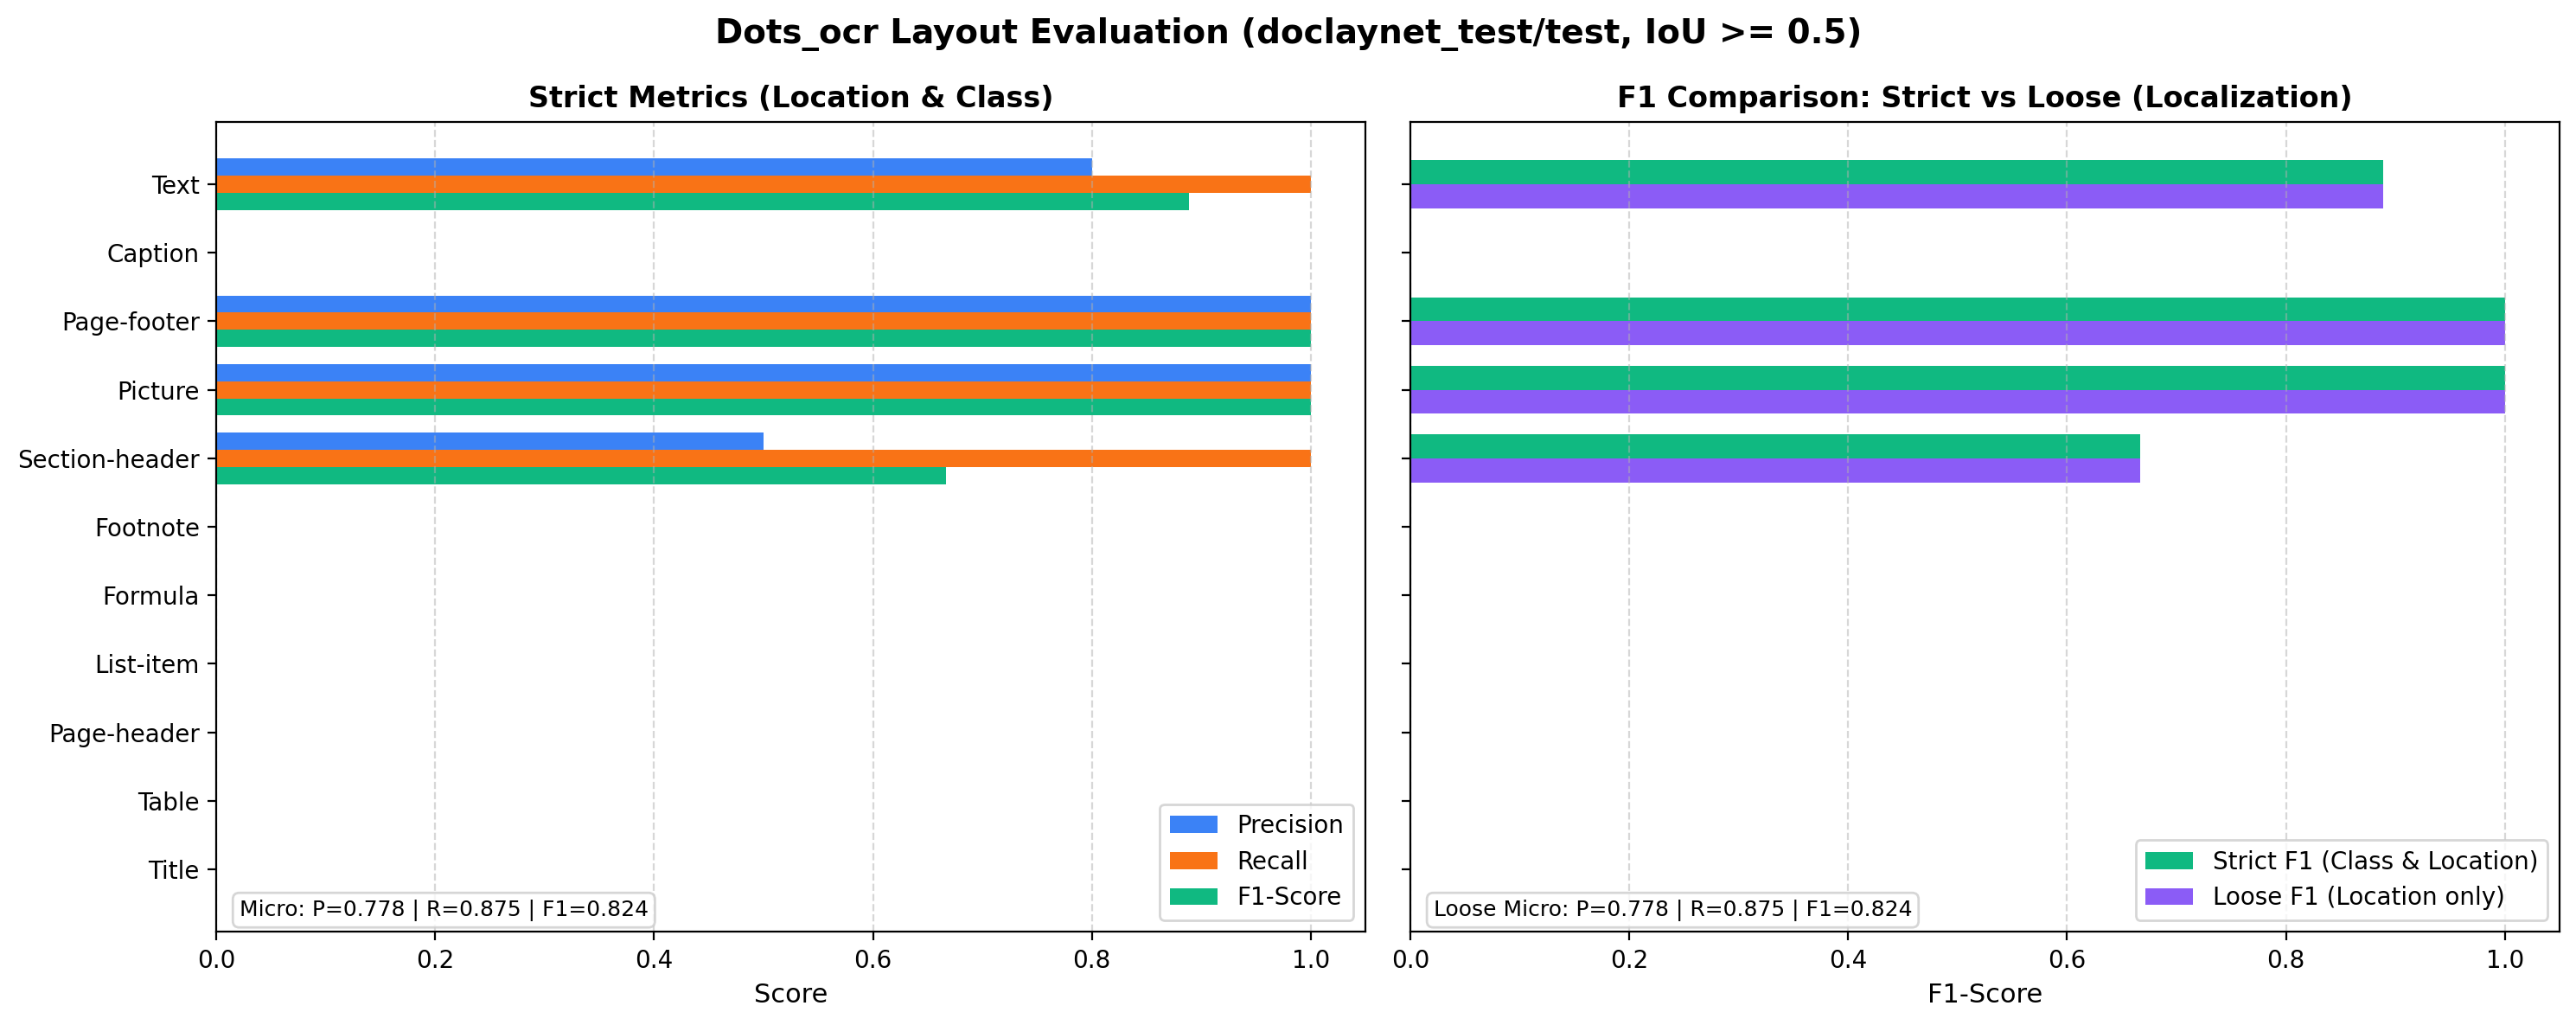

In [4]:
eval_script = ROOT / "scripts" / "evaluate_predictions.py"
chart_path = FIGURES_DIR / "metrics_chart.png"
chart_path.parent.mkdir(parents=True, exist_ok=True)

cmd = [
    sys.executable,
    str(eval_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", str(IOU_THRESHOLD),
    "--allow-incomplete",
    "--loose",
    "--plot", str(chart_path),
]

print("Running evaluation:")
res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), encoding="utf-8", errors="replace")
print(res.stdout)
if res.stderr:
    print("Errors / Warnings:", res.stderr[-500:])

if chart_path.exists():
    from IPython.display import Image, display
    print(f"\nEvaluation Chart ({chart_path}):")
    display(Image(filename=str(chart_path)))


## 3. Ground Truth vs. Prediction Examples

Vẽ bounding box Ground Truth (bên trái) đối chiếu với dự đoán của dots.ocr (bên phải) cạnh nhau trên cùng một ảnh để trực quan hóa chất lượng nhận diện layout.

Running: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\visualize_predictions.py --method dots_ocr --dataset doclaynet_test --split test --limit 1 --output-dir D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\dots_ocr_doclaynet_test


[viz] Ve 1 anh (dots_ocr vs ground truth) tu D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\..\..\outputs\predictions\dots_ocr\doclaynet_test
  [ok] 1.png
[viz] Xong. Anh luu tai D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\dots_ocr_doclaynet_test


Hiển thị 1 ảnh mẫu (Ground Truth vs dots_ocr):
Ảnh: 1.png


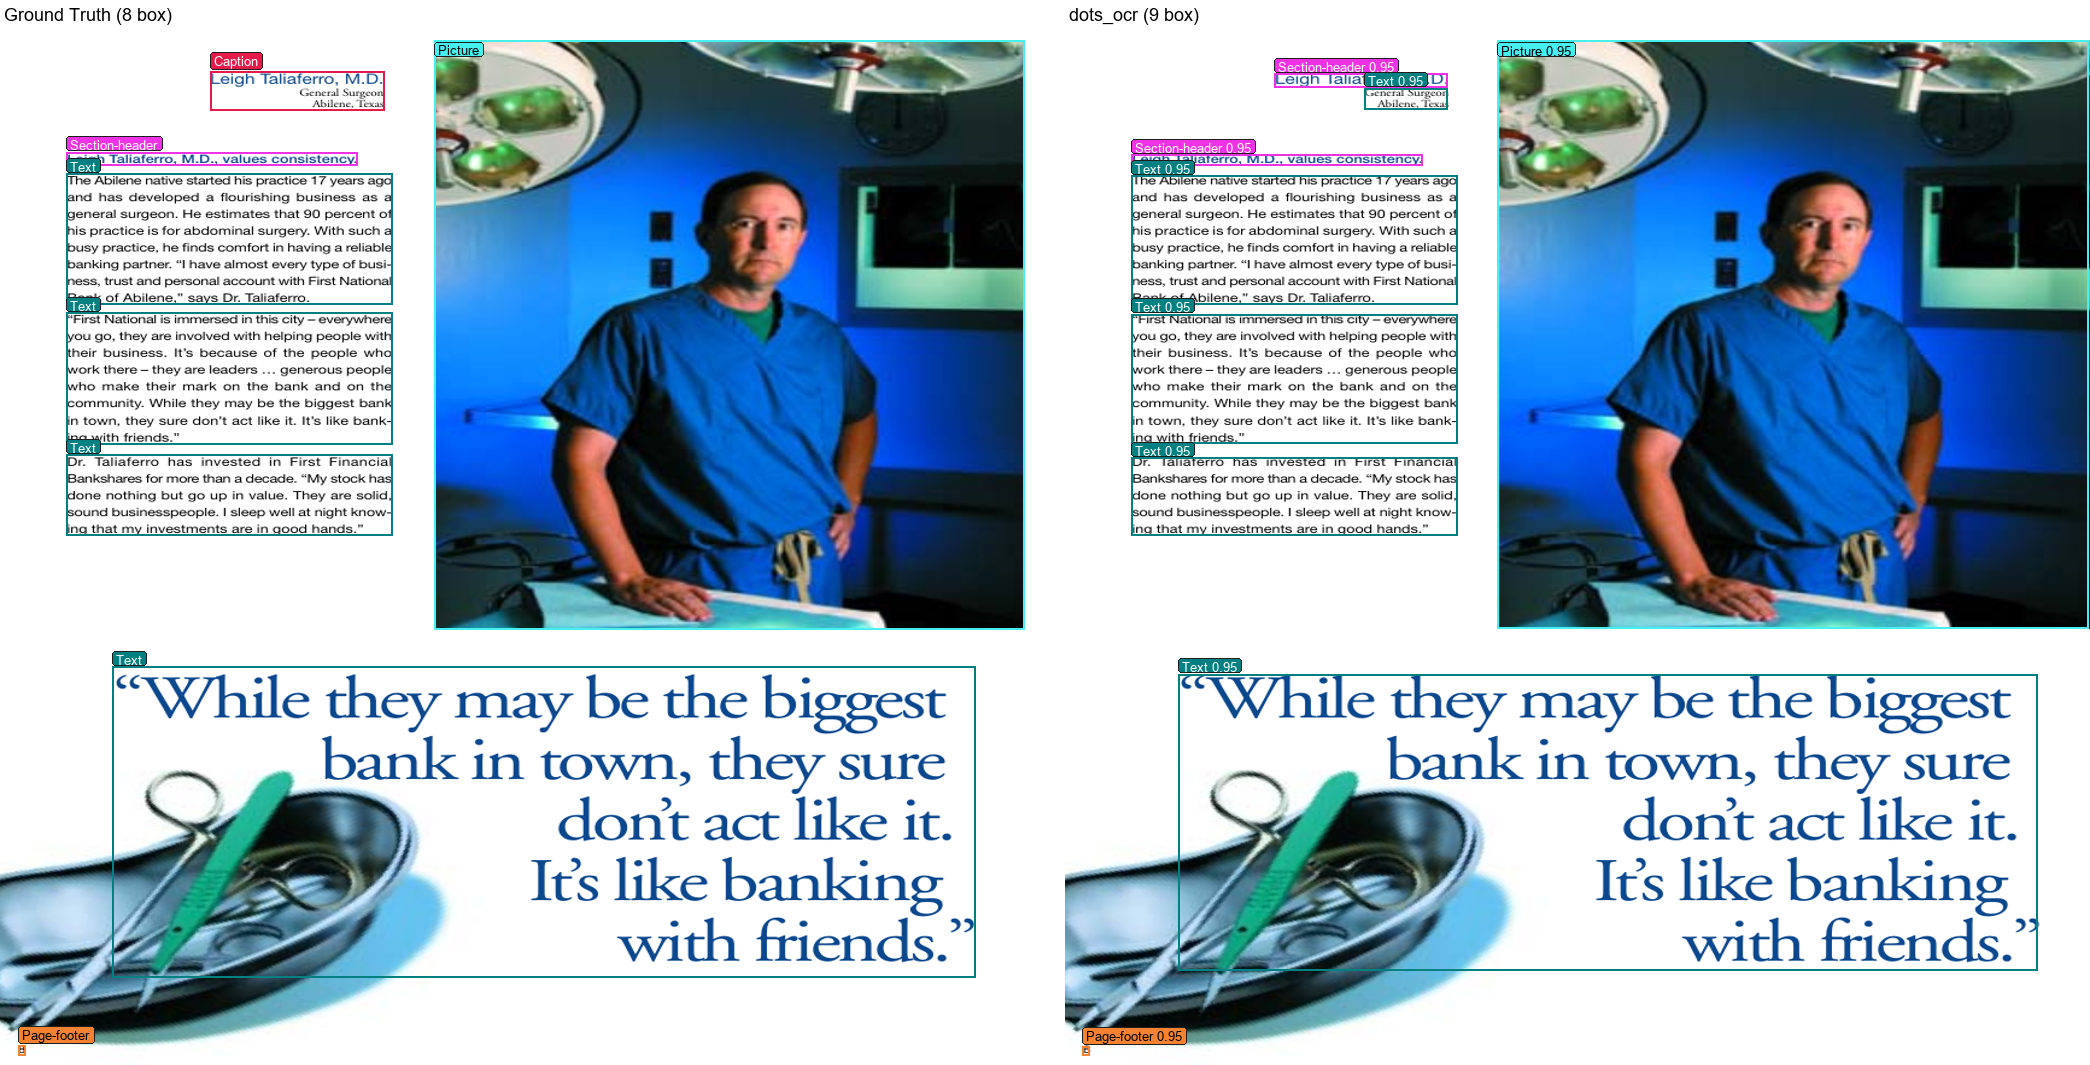

In [5]:
viz_script = ROOT / "visualization" / "scripts" / "visualize_predictions.py"
cmd = [
    sys.executable,
    str(viz_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", str(FIGURE_LIMIT),
    "--output-dir", str(FIGURES_DIR),
]

print(f"Running: {' '.join(cmd)}")
res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), encoding="utf-8", errors="replace")
print(res.stdout)
if res.stderr:
    print("Errors / Warnings:", res.stderr[-500:])

import glob
from IPython.display import Image, display

fig_files = sorted(FIGURES_DIR.glob("*.png"))
sample_files = [f for f in fig_files if f.name != "metrics_chart.png"][:4]
print(f"\nHiển thị {len(sample_files)} ảnh mẫu (Ground Truth vs {METHOD}):")
for f in sample_files:
    print(f"Ảnh: {f.name}")
    display(Image(filename=str(f)))
